## Evaluation and validation of borehole heat transfer in a single U-tube borehole

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pygfunction3 as gt3
import pygfunction as gt

#### Borehole parameters
A straight vertical borehole located at the origin (x=0, y=0) is used since the model is only dependent on the longitudinal position along the borehole.

In [2]:
# Borehole dimensions
L = 150.      # Borehole length (in meters)
D = 4.        # Borehole buried depth (in meters)
r_b = 0.070   # Borehole radius (in meters)
x = 0.        # Borehole position x on the horizontal plane (in meters)
y = 0.        # Borehole position y on the horizontal plane (in meters)
borehole = gt3.Borehole(L, D, r_b, [x, y])

# Pipe dimensions
n_p = 2             # Number of pipes
# Pipe inner radius (m)
r_p_in = 0.018 * np.ones(n_p)
# Pipe outer radius (m)
r_p_out = 0.02 * np.ones(n_p)

# Pipe positions
# Single U-tube [(x_1, y_1), (x_2, y_2)]
p = [(0.03, 0.00), (-0.03, 0.02)]

# Pipe properties
k_p = 0.4           # Pipe thermal conductivity (W/m.K)
epsilon = 2.12e-5   # Pipe roughness (in meters)

# Ground properties
k_s = 2.5           # Ground thermal conductivity (W/m.K)

# Grout properties
k_b = 1.5           # Grout thermal conductivity (W/m.K)

#### Fluid Properties
The fluid is propylene-glycol (20%).

In [3]:
m_flow = 0.1      # Fluid mass flow rate (in kg/s)
T_nominal = 20.
fluid = gt3.Fluid.from_scp(
    'PropyleneGlycol', T_nominal, x=0.2
)
cp_f = fluid.specific_heat()  # Fluid specific heat capacity (in J/kg.K)

#### Simulation conditions

In [4]:
# Inlet fluid temperature (in degrees Celsius)
T_f_in = -1.
# Borehole wall temperature (in degrees Celsius)
f_T_b = lambda _xi, _N: 1. + _xi**(_N - 1) - _xi / 3

### Solution using pygfunction3

#### Parameters for the evaluation of the borehole heat transfer

In [5]:
# Basis functions
n_nodes = 11
basis = gt3.Basis(n_nodes)
# Evaluation points
T_b_nodes = f_T_b(basis.xi, basis.n_nodes)
n_eval = 201
xi_eval = np.linspace(-1., 1., num=n_eval)
s_eval = borehole.longitudinal_position(xi_eval)
T_b_eval = f_T_b(xi_eval, basis.n_nodes)

In [6]:
# Pipe object
pipe = gt3.pipe.SingleUTube(p, r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon)
pipe_reversed = gt3.pipe.SingleUTube(p[::-1], r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon)

# Fluid temperature profile along the borehole
T_f = pipe.temperature(borehole, basis, xi_eval, m_flow, T_f_in, T_b_nodes)
T_f_reversed = pipe_reversed.temperature(borehole, basis, xi_eval, -m_flow, T_f_in, T_b_nodes)
# Outlet fluid temperature
T_f_out = pipe.outlet_temperature(borehole, basis, m_flow, T_f_in, T_b_nodes)
T_f_out_reversed = pipe_reversed.outlet_temperature(borehole, basis, -m_flow, T_f_in, T_b_nodes)
# Heat extraction rate along the borehole
q = pipe.heat_extraction_rate(borehole, basis, xi_eval, m_flow, T_f_in, T_b_nodes)
q_reversed = pipe_reversed.heat_extraction_rate(borehole, basis, xi_eval, -m_flow, T_f_in, T_b_nodes)
# Average heat extraction rate
q_avg = pipe.average_heat_extraction_rate(borehole, basis, m_flow, T_f_in, T_b_nodes)
q_avg_reversed = pipe_reversed.average_heat_extraction_rate(borehole, basis, -m_flow, T_f_in, T_b_nodes)
# Effective borehole thermal resistance
R_b = pipe.effective_borehole_thermal_resistance(borehole, m_flow)
R_b_reversed = pipe_reversed.effective_borehole_thermal_resistance(borehole, -m_flow)

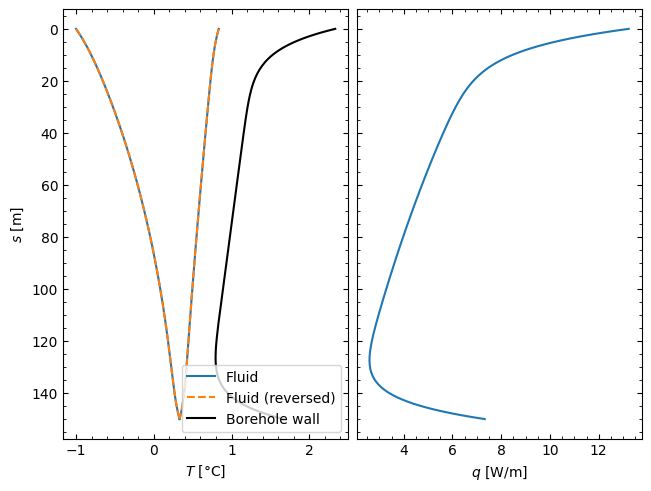

In [7]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$T$ [°C]', '$s$ [m]'], inverse_y=True)
line = axs[0].plot(T_f[:, 0], s_eval, label='Fluid')
axs[0].plot(T_f[:, 1:], s_eval, color=line[0].get_color())
line = axs[0].plot(T_f_reversed[:, 0], s_eval, '--', label='Fluid (reversed)')
axs[0].plot(T_f_reversed[:, 1:], s_eval, '--', color=line[0].get_color())
axs[0].plot(T_b_eval, s_eval, 'k-', label='Borehole wall')
axs[0].legend()
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel('$q$ [W/m]')
axs[1].plot(q, s_eval)
plt.show()

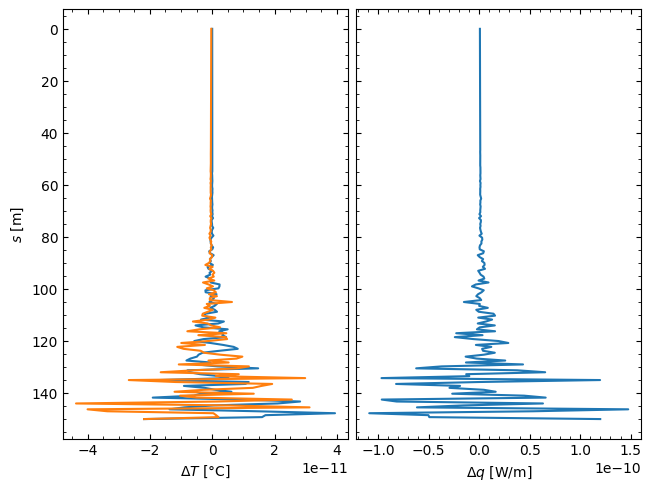

In [8]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$\Delta T$ [°C]', '$s$ [m]'], inverse_y=True)
line = axs[0].plot(T_f - np.flip(T_f_reversed, axis=1), s_eval)
# axs[0].legend()
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel(r'$\Delta q$ [W/m]')
axs[1].plot(q - q_reversed, s_eval)
plt.show()

### Solution using pygfunction2

In [9]:
# Borehole object
borehole_pygfunction = gt.boreholes.Borehole(L, D, r_b, x, y)
# Evaluation points
n_segments = 51
xi_edges = np.linspace(-1., 1., num=n_segments + 1)
xi_segments = 0.5 * (xi_edges[1:] + xi_edges[:-1])
s_segments = borehole.longitudinal_position(xi_segments)
T_b_segments = f_T_b(xi_segments, n_nodes)

In [10]:
# Pipe object
h_fluid = gt.pipes.convective_heat_transfer_coefficient_circular_pipe(
    m_flow,
    r_p_in[0],
    fluid.viscosity(),
    fluid.density(),
    fluid.conductivity(),
    fluid.specific_heat(),
    epsilon
)
R_fluid = 1. / (h_fluid * 2. * np.pi * r_p_in[0])
R_pipe = gt.pipes.conduction_thermal_resistance_circular_pipe(
    r_p_in[0], r_p_out[0], k_p
)
R_fp = R_fluid + R_pipe
pipe_pygfunction = gt.pipes.SingleUTube(
    p, r_p_in[0], r_p_out[0], borehole_pygfunction, k_s, k_b, R_fp, J=3
)

# Fluid temperature profile along the borehole
T_f_pygfunction = pipe_pygfunction.get_temperature(s_eval, T_f_in, T_b_segments, m_flow, np.array([cp_f]))
# Outlet fluid temperature
T_f_out_pygfunction = pipe_pygfunction.get_outlet_temperature(T_f_in, T_b_segments, m_flow, np.array([cp_f]))
# Heat extraction rate along the borehole
q_pygfunction = pipe_pygfunction.get_borehole_heat_extraction_rate(T_f_in, T_b_segments, m_flow, np.array([cp_f])) * n_segments / borehole_pygfunction.H
# Average heat extraction rate
q_avg_pygfunction = pipe_pygfunction.get_total_heat_extraction_rate(T_f_in, T_b_segments, m_flow, np.array([cp_f])) / borehole_pygfunction.H
# Effective borehole thermal resistance
R_b_pygfunction = pipe_pygfunction.effective_borehole_thermal_resistance(m_flow, np.array([cp_f]))

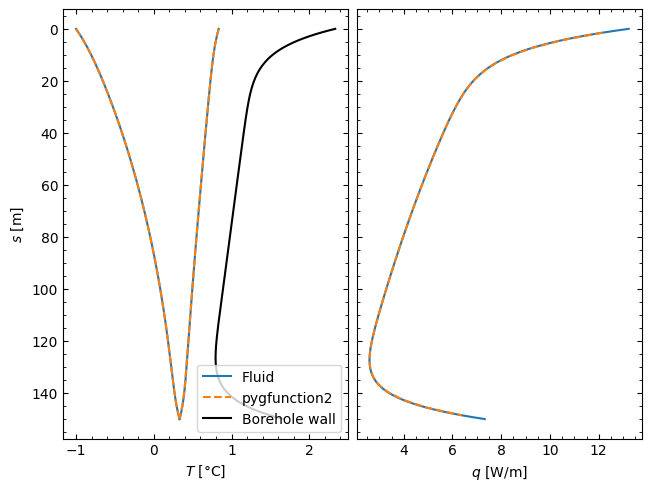

In [11]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$T$ [°C]', '$s$ [m]'], inverse_y=True)
line = axs[0].plot(T_f[:, 0], s_eval, label='Fluid')
axs[0].plot(T_f[:, 1:], s_eval, color=line[0].get_color())
line = axs[0].plot(T_f_pygfunction[:, 0], s_eval, '--', label='pygfunction2')
axs[0].plot(T_f_pygfunction[:, 1:], s_eval, '--', color=line[0].get_color())
axs[0].plot(T_b_eval, s_eval, 'k-', label='Borehole wall')
axs[0].legend()
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel('$q$ [W/m]')
axs[1].plot(q, s_eval)
axs[1].plot(q_pygfunction, s_segments, '--')
plt.show()

### Solution using a finite difference model
A finite difference model is used for validation of the solution. The finite difference model uses evenly spaced longitudinal positions $s_i$ along the length of each pipe. The finite difference model solves the system of differential equations:
$$
\begin{align}
\dot{m}_f c_{p,f} \frac{dT_{f,1}}{ds} &= \frac{T_b(s) - T_{f,1}(s)}{R_{11}^\Delta} + \frac{T_{f,2}(s) - T_{f,1}(s)}{R_{12}^\Delta} \\
-\dot{m}_f c_{p,f} \frac{dT_{f,2}}{ds} &= \frac{T_b(s) - T_{f,2}(s)}{R_{22}^\Delta} + \frac{T_{f,1}(s) - T_{f,2}(s)}{R_{21}^\Delta} \\
\end{align}
$$
where $\dot{m}_f$ is the fluid mass flow rate, $c_{p,f}$ is the fluid specific heat capacity, $R_{ij}^\Delta$ are the delta-circuit thermal resistances, 
$T_{f,1}(s)$ and $T_{f,2}(s)$ are the fluid temperatures in the downward and upward flowing pipes at a longitudinal position $s$ and $T_b(s)$ is the borehole wall temeprature.

In discrete form:
$$
\begin{align}
\dot{m}_f c_{p,f} \frac{T_{f,1}(s_i) - T_{f,1}(s_{i-1})}{s_i - s_{i-1}} &= \frac{T_b(\frac{s_i + s_{i-1}}{2}) - \frac{1}{2} T_{f,1}(s_i) - \frac{1}{2} T_{f,1}(s_{i-1})}{R_{11}^\Delta} + \frac{\frac{1}{2} T_{f,2}(s_i) + \frac{1}{2} T_{f,2}(s_{i-1}) - \frac{1}{2} T_{f,1}(s_i) - \frac{1}{2} T_{f,1}(s_{i-1})}{R_{12}^\Delta} \\
-\dot{m}_f c_{p,f} \frac{T_{f,2}(s_i) - T_{f,2}(s_{i-1})}{s_i - s_{i-1}} &= \frac{T_b(\frac{s_i + s_{i-1}}{2}) - \frac{1}{2} T_{f,2}(s_i) - \frac{1}{2} T_{f,2}(s_{i-1})}{R_{22}^\Delta} + \frac{\frac{1}{2} T_{f,1}(s_i) + \frac{1}{2} T_{f,1}(s_{i-1}) - \frac{1}{2} T_{f,2}(s_i) - \frac{1}{2} T_{f,2}(s_{i-1})}{R_{21}^\Delta} \\
\end{align}
$$

In [12]:
class FiniteDifferenceSingleUTube:

    def __init__(self, R_d, L, num=101):
        self.R_d = R_d
        self.L = L
        self.num = num
        self.s = np.linspace(0., L, num=num)

    def solve(self, T_f_in, f_T_b, m_flow, cp_f):
        A = self.system_of_equations(m_flow, cp_f)
        B = self.boundary_condition(T_f_in, f_T_b, m_flow, cp_f)
        X = np.linalg.solve(A, B)
        T_f = X.reshape(-1, 2, order='F')
        xi = np.linspace(-1., 1., num=self.num)
        T_b = f_T_b(xi)
        R_b = self.R_d[0, 0] * self.R_d[1, 1] / (self.R_d[0, 0] + self.R_d[1, 1])
        q = T_b / R_b - T_f[:, 0] / self.R_d[0, 0] - T_f[:, 1] / self.R_d[1, 1]
        return q, T_f

    def boundary_condition(self, T_f_in, f_T_b, m_flow, cp_f):
        xi = np.linspace(-1., 1., num=self.num)
        xi = 0.5 * (xi[:-1] + xi[1:])
        T_b = f_T_b(xi)
        ds = self.L / (self.num - 1.)
        beta_1 = 1. / (m_flow * cp_f * self.R_d[0, 0])
        beta_12 = 1. / (m_flow * cp_f * self.R_d[0, 1])
        beta_2 = 1. / (m_flow * cp_f * self.R_d[1, 1])
        B = np.concatenate([np.array([T_f_in]), ds * beta_1 * T_b, ds * beta_2 * T_b, np.zeros(1)])     
        return B

    def system_of_equations(self, m_flow, cp_f):
        ds = self.L / (self.num - 1.)
        beta_1 = 1. / (m_flow * cp_f * self.R_d[0, 0])
        beta_12 = 1. / (m_flow * cp_f * self.R_d[0, 1])
        beta_2 = 1. / (m_flow * cp_f * self.R_d[1, 1])
        N = self.num - 1
        A_11 = (1. + 0.5 * ds * (beta_1 + beta_12)) * np.eye(N, M=N+1, k=1)
        A_11 = A_11 + (-1. + 0.5 * ds * (beta_1 + beta_12)) * np.eye(N, M=N+1, k=0)
        A_12 = -0.5 * ds * beta_12 * np.eye(N, M=N+1, k=1)
        A_12 = A_12 - 0.5 * ds * beta_12 * np.eye(N, M=N+1, k=0)
        A_21 = -0.5 * ds * beta_12 * np.eye(N, M=N+1)
        A_21 = A_21 - 0.5 * ds * beta_12 * np.eye(N, M=N+1, k=1)
        A_22 = (1. + 0.5 * ds * (beta_2 + beta_12)) * np.eye(N, M=N+1)
        A_22 = A_22 + (-1. + 0.5 * ds * (beta_2 + beta_12)) * np.eye(N, M=N+1, k=1)
        A = np.block(
            [[np.eye(1), np.zeros((1, 2 * N + 1))],
             [A_11, A_12],
             [A_21, A_22],
             [np.zeros((1, N)), -np.eye(1), np.zeros((1, N)), np.eye(1)]]
        )
        return A

In [13]:
borehole_FD = FiniteDifferenceSingleUTube(pipe.thermal_resistances(m_flow), L, num=n_eval)

# Heat extraction rate and fluid temperature profile along the borehole
q_FD, T_f_FD = borehole_FD.solve(T_f_in, lambda _xi: f_T_b(_xi, n_nodes), m_flow, cp_f)
# Outlet fluid temperature
T_f_out_FD = T_f_FD[0, -1]
# Average heat extraction rate
q_avg_FD = 0.5 * np.mean(q_FD[:-1] + q_FD[1:])

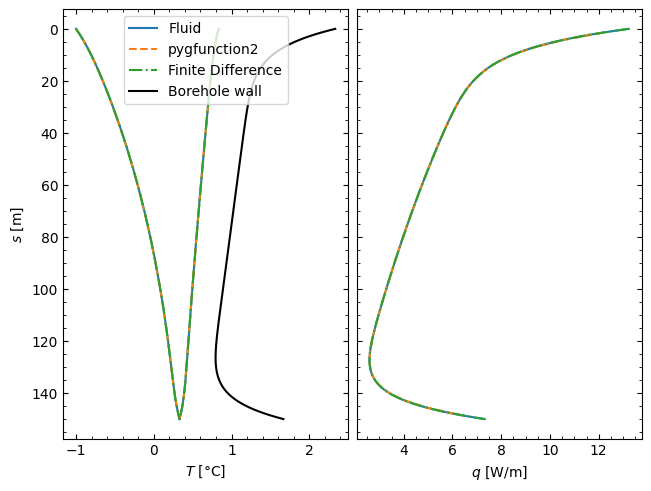

In [14]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$T$ [°C]', '$s$ [m]'], inverse_y=True)
line = axs[0].plot(T_f[:, 0], s_eval, label='Fluid')
axs[0].plot(T_f[:, 1:], s_eval, color=line[0].get_color())
line = axs[0].plot(T_f_pygfunction[:, 0], s_eval, '--', label='pygfunction2')
axs[0].plot(T_f_pygfunction[:, 1:], s_eval, '--', color=line[0].get_color())
line = axs[0].plot(T_f_FD[:, 0], s_eval, '-.', label='Finite Difference')
axs[0].plot(T_f_FD[:, 1:], s_eval, '-.', color=line[0].get_color())
axs[0].plot(T_b_eval, s_eval, 'k-', label='Borehole wall')
axs[0].legend()
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel('$q$ [W/m]')
axs[1].plot(q, s_eval)
axs[1].plot(q_pygfunction, s_segments, '--')
axs[1].plot(q_FD, s_eval, '-.')
plt.show()

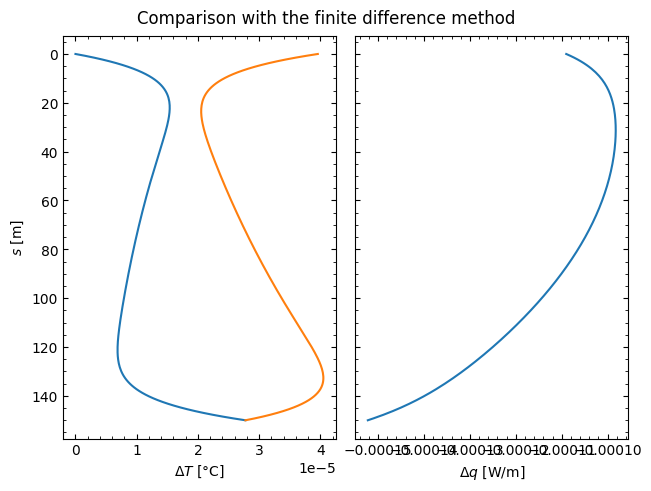

In [15]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
fig.suptitle('Comparison with the finite difference method')
axs[0] = gt3.plot._format_axis(axs[0], [r'$\Delta T$ [°C]', '$s$ [m]'], inverse_y=True)
line = axs[0].plot(T_f - T_f_FD, s_eval, label='Fluid')
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel(r'$\Delta q$ [W/m]')
axs[1].plot(q - q_FD, s_eval)
plt.show()

In [16]:
print(f'Outlet fluid temperature (pygfunction3): {T_f_out:.4f} °C')
print(f'Outlet fluid temperature (pygfunction3, reversed): {T_f_out_reversed:.4f} °C')
print(f'Outlet fluid temperature (pygfunction2): {T_f_out_pygfunction:.4f} °C')
print(f'Outlet fluid temperature (Finite Difference): {T_f_out_FD:.4f} °C')
print(f'Average heat extraction rate (pygfunction3): {q_avg:.4f} W/m')
print(f'Average heat extraction rate (pygfunction3, reversed): {q_avg_reversed:.4f} W/m')
print(f'Average heat extraction rate (pygfunction2): {q_avg_pygfunction:.4f} W/m')
print(f'Average heat extraction rate (Finite Difference): {q_avg_FD:.4f} W/m')
print(f'Effective borehole thermal resistance (pygfunction3): {R_b:.6f} K.m/W')
print(f'Effective borehole thermal resistance (pygfunction3, reversed): {R_b_reversed:.6f} K.m/W')
print(f'Effective borehole thermal resistance (pygfunction2): {R_b_pygfunction:.6f} K.m/W')

Outlet fluid temperature (pygfunction3): 0.8348 °C
Outlet fluid temperature (pygfunction3, reversed): 0.8348 °C
Outlet fluid temperature (pygfunction2): 0.8341 °C
Outlet fluid temperature (Finite Difference): 0.8347 °C
Average heat extraction rate (pygfunction3): 4.8643 W/m
Average heat extraction rate (pygfunction3, reversed): 4.8643 W/m
Average heat extraction rate (pygfunction2): 4.8626 W/m
Average heat extraction rate (Finite Difference): 4.8649 W/m
Effective borehole thermal resistance (pygfunction3): 0.248735 K.m/W
Effective borehole thermal resistance (pygfunction3, reversed): 0.248735 K.m/W
Effective borehole thermal resistance (pygfunction2): 0.248735 K.m/W
